In [1]:
import os
os.environ["PYTHONPATH"] = ""

In [2]:
import pennylane as qml
from pennylane import numpy as np
from pennylane.templates import RandomLayers
import tensorflow as tf
from tensorflow import keras
import matplotlib.pyplot as plt
import math
import time

I0000 00:00:1775525049.789283 2411829 port.cc:153] oneDNN custom operations are on. You may see slightly different numerical results due to floating-point round-off errors from different computation orders. To turn them off, set the environment variable `TF_ENABLE_ONEDNN_OPTS=0`.
I0000 00:00:1775525049.855900 2411829 cpu_feature_guard.cc:227] This TensorFlow binary is optimized to use available CPU instructions in performance-critical operations.
To enable the following instructions: AVX2 AVX512F AVX512_VNNI FMA, in other operations, rebuild TensorFlow with the appropriate compiler flags.
I0000 00:00:1775525054.351752 2411829 port.cc:153] oneDNN custom operations are on. You may see slightly different numerical results due to floating-point round-off errors from different computation orders. To turn them off, set the environment variable `TF_ENABLE_ONEDNN_OPTS=0`.


In [3]:
# ================================================================
#  EXPERIMENT CONFIGURATION — edit everything here
# ================================================================

# --- Hardware ---
CUDA_DEVICE      = "0"          # GPU index ("0", "1", "2", ...)

# --- Dataset ---
TARGET_LABELS    = [3, 5]       # Two MNIST classes to distinguish
PER_CLASS_TRAIN  = 300           # Training samples per class
PER_CLASS_TEST   = 60           # Test samples per class

# --- Quantum feature layer (PennyLane quanvolution) ---
Q_FILTER_SIZE    = 2            # Filter width/height; uses size^2 qubits
Q_FILTER_LAYERS  = 1            # Random circuit layers = output channels / size^2
Q_STRIDE         = 2            # Stride of the quantum filter
Q_PADDING        = 0            # Padding (not yet implemented)

# --- TensorFlow models (Q+Dense, Classical Dense, QC-CNN, Classical CNN) ---
TF_EPOCHS        = 100          # Training epochs
TF_LR            = 0.001        # Learning rate
TF_BATCH_SIZE    = 4            # Mini-batch size

# --- QCQ-CNN (PyTorch hybrid quantum-classical-quantum) ---
QCQ_EPOCHS       = 100           # Training epochs
QCQ_LR           = 0.0005        # Adam learning rate
QCQ_SEED         = 42           # Random seed for reproducibility

# --- Cache filenames (auto-derived — do not edit) ---
TRAIN_CACHE = (f'MNIST_op_train'
               f'_{TARGET_LABELS[0]}v{TARGET_LABELS[1]}'
               f'_{PER_CLASS_TRAIN}pc.npy')
TEST_CACHE  = (f'MNIST_op_test'
               f'_{TARGET_LABELS[0]}v{TARGET_LABELS[1]}'
               f'_{PER_CLASS_TEST}pc.npy')

# ================================================================
print("Config loaded:")
print(f"  Dataset  : MNIST {TARGET_LABELS[0]} vs {TARGET_LABELS[1]}"
      f"  |  {PER_CLASS_TRAIN} train / {PER_CLASS_TEST} test per class")
print(f"  Q-filter : size={Q_FILTER_SIZE}, layers={Q_FILTER_LAYERS},"
      f" stride={Q_STRIDE}, padding={Q_PADDING}")
print(f"  TF models: {TF_EPOCHS} epochs, lr={TF_LR}, batch={TF_BATCH_SIZE}")
print(f"  QCQ-CNN  : {QCQ_EPOCHS} epochs, lr={QCQ_LR}, seed={QCQ_SEED}")
print(f"  Cache    : {TRAIN_CACHE}")
print(f"           : {TEST_CACHE}")


Config loaded:
  Dataset  : MNIST 3 vs 5  |  300 train / 60 test per class
  Q-filter : size=2, layers=1, stride=2, padding=0
  TF models: 100 epochs, lr=0.001, batch=4
  QCQ-CNN  : 100 epochs, lr=0.0005, seed=42
  Cache    : MNIST_op_train_3v5_300pc.npy
           : MNIST_op_test_3v5_60pc.npy


In [4]:
import os
os.environ["CUDA_VISIBLE_DEVICES"] = CUDA_DEVICE


In [5]:
from tensorflow import keras
import numpy as np

# 加载 MNIST 数据
(train_images, train_labels), (test_images, test_labels) = keras.datasets.mnist.load_data()

# 筛选标签为 TARGET_LABELS 的图像
train_mask = np.isin(train_labels, TARGET_LABELS)
test_mask  = np.isin(test_labels,  TARGET_LABELS)

train_images = train_images[train_mask]
train_labels = train_labels[train_mask]
test_images  = test_images[test_mask]
test_labels  = test_labels[test_mask]

# 将标签映射为 0 和 1
train_labels = (train_labels == TARGET_LABELS[1]).astype(np.int32)
test_labels  = (test_labels  == TARGET_LABELS[1]).astype(np.int32)

def select_balanced_subset(images, labels, per_class_train, per_class_test):
    selected_train_images, selected_train_labels = [], []
    selected_test_images,  selected_test_labels  = [], []

    for label_val in [0, 1]:
        train_idx = np.where(labels      == label_val)[0][:per_class_train]
        test_idx  = np.where(test_labels == label_val)[0][:per_class_test]
        selected_train_images.append(images[train_idx])
        selected_train_labels.append(labels[train_idx])
        selected_test_images.append(test_images[test_idx])
        selected_test_labels.append(test_labels[test_idx])

    return (np.concatenate(selected_train_images),
            np.concatenate(selected_train_labels),
            np.concatenate(selected_test_images),
            np.concatenate(selected_test_labels))

train_images, train_labels, test_images, test_labels = select_balanced_subset(
    train_images, train_labels,
    per_class_train=PER_CLASS_TRAIN,
    per_class_test=PER_CLASS_TEST,
)

# 归一化 & 添加通道维度
train_images = train_images / 255.0
test_images  = test_images  / 255.0
train_images = train_images[..., np.newaxis]
test_images  = test_images[...,  np.newaxis]

print("Train:", train_images.shape, train_labels.shape)
print("Test :", test_images.shape,  test_labels.shape)


Train: (600, 28, 28, 1) (600,)
Test : (120, 28, 28, 1) (120,)


In [6]:

class Quanvolutional_Layer():

  def __init__(self,size_filter,layers_filter,stride_filter,padding):
    self.size_filter   = size_filter         # Determines the number of qubits to be required for the random cicuit (2-4)[time increases NP hard]
    self.layers_filter = layers_filter       # Number of random circuits since each filter is a realization of a circuit
    self.stride_filter = stride_filter       # Stride same meaning as classical counterpart
    self.padding       = padding             # Experimental feature ***Not Implemented***

    # Circuit design i.e. number of qubits required for encoding
    self.dev           = qml.device("default.qubit", wires=self.size_filter*self.size_filter)

    # Along each circuit we require (filter_size)^2 parameters randomly initialized
    self.rand_params   = np.random.uniform(high=2 * np.pi, size=(self.layers_filter, (self.size_filter*self.size_filter)))
    print("Created Basic Properties")


  # The qfilter generted will have the following gate properties :
  # 1) Encoding  : Ry rotation gate where the angles are scaled by PI
  # 2) Ciruit    : Of n_layers random in nature
  # 3) Decoding  : 4 expectation value measurements
  # decorator for quantum node
  def creator(self,phi):
    # Due the decorator access we specified a function inside another function

    @qml.qnode(self.dev)
    def circuit(phi):
      # List containg all qubit outputs
      op_list = []

      # Encoding on each of the filter value along each wire
      for j in range(self.size_filter*self.size_filter):
        qml.RY(np.pi * phi[j], wires=j) # BloC sphere mapping

      # Random quantum circuit generation based on the random paramters we chose
      # The first dimension of rand_params (adjusts the number of layers we care about they are weights)
      # Iterating one filter at a time
      for k in self.rand_params:
        tmp = np.expand_dims(k,axis=0) # convert into 1 layer, number of qubits
        RandomLayers(tmp, wires=list(range(self.size_filter*self.size_filter)))
        for j in range(self.size_filter*self.size_filter):
          op_list.append(qml.expval(qml.PauliZ(j)))
      return op_list

    # op_list of shape : number of filters, number of qubits
    op_list = circuit(phi)
    op_list = np.array(op_list)
    return list(np.reshape(op_list, (self.layers_filter, (self.size_filter*self.size_filter))))

  def call(self,image):

    # Sanity check wether the paramters specified is alright for the image dimensions
    calc = math.floor((image.shape[1]+2*self.padding-self.size_filter)/self.stride_filter) + 1
    if calc <1:
      return -1
    # Stide reductions along the height and width dim & filter size = number of filters * number of qubits
    out = np.zeros((calc,calc,self.layers_filter*(self.size_filter*self.size_filter)))
    print(image.shape)
    print(out.shape)
    

    # Output collection array
    collection = []
    index = 0
    for i in image:
      out = np.zeros((calc,calc,self.layers_filter*(self.size_filter*self.size_filter)))
      # Progress checker
      print("Image processed :",index+1)
      # Stride based steps
      for j in range(0, i.shape[0], self.stride_filter):
        for k in range(0, i.shape[1], self.stride_filter):
          phi = []
          # Padding not yet implemented
          if(j+self.size_filter > i.shape[0]) | (k+self.size_filter > i.shape[1]):
            continue
          for l in range(j,j+self.size_filter): 
            for m in range(k,k+self.size_filter):
              phi.append(i[l][m][0])
              
          q_results = self.creator(phi)
          
          ctr = 0
          for x in q_results:
            for y in range(len(x)):
              out[j//self.stride_filter, k//self.stride_filter,ctr] = x[y]
              ctr+=1
      collection.append(out) 
      index+=1
    return collection


In [7]:
# Only compute quantum features if cached files don't exist.
# Cache filenames are auto-derived from config — changing dataset params auto-invalidates them.
if not (os.path.exists(TRAIN_CACHE) and os.path.exists(TEST_CACHE)):
    print("Computing quantum features (first run — will be cached)...")
    Quan2D = Quanvolutional_Layer(Q_FILTER_SIZE, Q_FILTER_LAYERS, Q_STRIDE, Q_PADDING)
    op_train = np.asarray(Quan2D.call(train_images), dtype=np.float32)
    op_test  = np.asarray(Quan2D.call(test_images),  dtype=np.float32)
    np.save(TRAIN_CACHE, op_train)
    np.save(TEST_CACHE,  op_test)
    print(f"Saved to {TRAIN_CACHE} / {TEST_CACHE}")
else:
    print(f"Loading cached quantum features...")
    print(f"  {TRAIN_CACHE}")
    print(f"  {TEST_CACHE}")
    op_train = np.load(TRAIN_CACHE)
    op_test  = np.load(TEST_CACHE)


Loading cached quantum features...
  MNIST_op_train_3v5_300pc.npy
  MNIST_op_test_3v5_60pc.npy


In [8]:
print(op_train.shape)
print(op_test.shape)
print(op_train[0])

(600, 14, 14, 4)
(120, 14, 14, 4)
[[[ 0.65960914  1.          1.          1.        ]
  [ 0.65960914  1.          1.          1.        ]
  [ 0.65960914  1.          1.          1.        ]
  [ 0.65960914  1.          1.          1.        ]
  [ 0.65960914  1.          1.          1.        ]
  [ 0.65960914  1.          1.          1.        ]
  [ 0.65960914  1.          1.          1.        ]
  [ 0.65960914  1.          1.          1.        ]
  [ 0.65960914  1.          1.          1.        ]
  [ 0.65960914  1.          1.          1.        ]
  [ 0.65960914  1.          1.          1.        ]
  [ 0.65960914  1.          1.          1.        ]
  [ 0.65960914  1.          1.          1.        ]
  [ 0.65960914  1.          1.          1.        ]]

 [[ 0.65960914  1.          1.          1.        ]
  [ 0.65960914  1.          1.          1.        ]
  [ 0.65960914  1.          1.          1.        ]
  [ 0.65960914  1.          1.          1.        ]
  [ 0.65960914  1.          

In [9]:
# Save/load is handled in the cell above (conditional on existence)
print("op_train shape:", op_train.shape)
print("op_test  shape:", op_test.shape)


op_train shape: (600, 14, 14, 4)
op_test  shape: (120, 14, 14, 4)


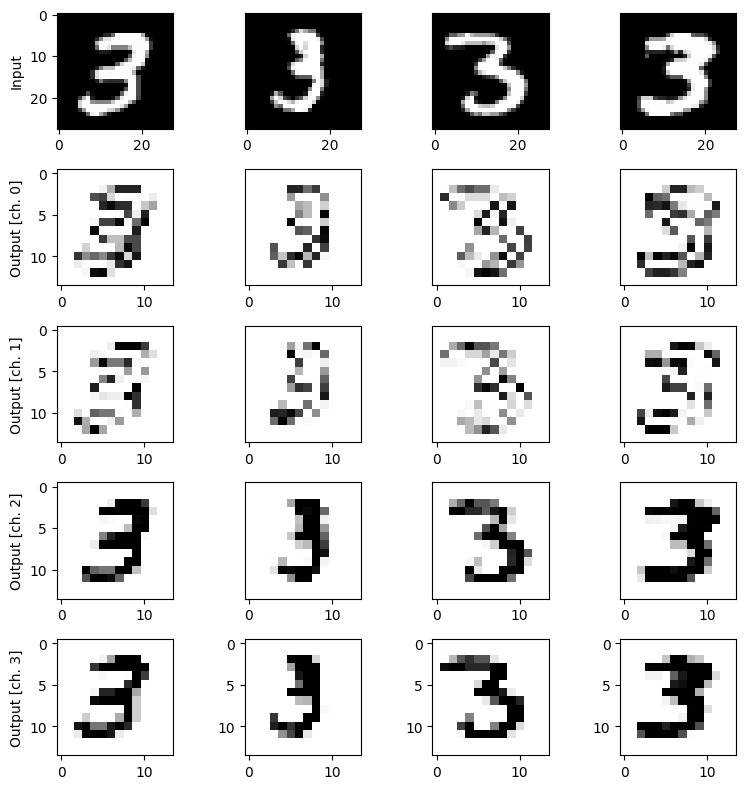

In [10]:
n_samples = 4
n_channels = 4
fig, axes = plt.subplots(1 + n_channels, n_samples, figsize=(8, 8))
for k in range(n_samples):
    axes[0, 0].set_ylabel("Input")
    if k != 0:
        axes[0, k].yaxis.set_visible(False)
    axes[0, k].imshow(train_images[k, :, :, 0], cmap="gray")

    # Plot all output channels
    for c in range(n_channels):
        axes[c + 1, 0].set_ylabel("Output [ch. {}]".format(c))
        if k != 0:
            axes[c, k].yaxis.set_visible(False)
        axes[c + 1, k].imshow(op_train[k, :, :, c], cmap="gray")

plt.tight_layout()
plt.show()

In [11]:
def MyModel():
    model = keras.models.Sequential([
            keras.layers.Flatten(),
            keras.layers.Dense(10, activation="softmax")
    ])
    
    model.compile(
            optimizer=keras.optimizers.SGD(learning_rate=lr),
            loss="sparse_categorical_crossentropy",
            metrics=["accuracy"],
    )
    return model

In [12]:
n_epochs = TF_EPOCHS
n_layers = Q_FILTER_LAYERS
n_train  = PER_CLASS_TRAIN * 2
n_test   = PER_CLASS_TEST  * 2
lr       = TF_LR
np.random.seed(QCQ_SEED)
tf.random.set_seed(QCQ_SEED)


In [13]:
q_model = MyModel()
q_history = q_model.fit(
    op_train, train_labels,
    validation_data=(op_test, test_labels),
    batch_size=TF_BATCH_SIZE,
    epochs=n_epochs,
    verbose=2,
)

Epoch 1/100


W0000 00:00:1775525058.146406 2411829 gpu_device.cc:2365] Cannot dlopen some GPU libraries. Please make sure the missing libraries mentioned above are installed properly if you would like to use GPU. Follow the guide at https://www.tensorflow.org/install/gpu for how to download and setup the required libraries for your platform.
Skipping registering GPU devices...


150/150 - 1s - 5ms/step - accuracy: 0.6333 - loss: 0.8292 - val_accuracy: 0.6833 - val_loss: 0.5980
Epoch 2/100
150/150 - 0s - 1ms/step - accuracy: 0.8067 - loss: 0.4625 - val_accuracy: 0.7833 - val_loss: 0.4825
Epoch 3/100
150/150 - 0s - 2ms/step - accuracy: 0.8683 - loss: 0.3697 - val_accuracy: 0.8333 - val_loss: 0.4203
Epoch 4/100
150/150 - 0s - 2ms/step - accuracy: 0.9000 - loss: 0.3173 - val_accuracy: 0.8417 - val_loss: 0.3802
Epoch 5/100
150/150 - 0s - 2ms/step - accuracy: 0.9167 - loss: 0.2830 - val_accuracy: 0.8583 - val_loss: 0.3518
Epoch 6/100
150/150 - 0s - 2ms/step - accuracy: 0.9250 - loss: 0.2584 - val_accuracy: 0.8667 - val_loss: 0.3304
Epoch 7/100
150/150 - 0s - 2ms/step - accuracy: 0.9333 - loss: 0.2397 - val_accuracy: 0.8667 - val_loss: 0.3136
Epoch 8/100
150/150 - 0s - 1ms/step - accuracy: 0.9350 - loss: 0.2249 - val_accuracy: 0.8750 - val_loss: 0.2999
Epoch 9/100
150/150 - 0s - 2ms/step - accuracy: 0.9367 - loss: 0.2128 - val_accuracy: 0.8750 - val_loss: 0.2886
Epoc

In [14]:
# 获取 accuracy 和 loss 历史
val_accuracies = q_history.history['val_accuracy']
val_losses = q_history.history['val_loss']

print("Validation Accuracy:")
for acc in val_accuracies:
    print(f"{acc:.4f}")

print("\nValidation Loss:")
for loss in val_losses:
    print(f"{loss:.4f}")

Validation Accuracy:
0.6833
0.7833
0.8333
0.8417
0.8583
0.8667
0.8667
0.8750
0.8750
0.8750
0.8833
0.8833
0.8917
0.8917
0.8917
0.8917
0.8917
0.8917
0.8833
0.8833
0.8833
0.8833
0.8917
0.8917
0.9000
0.9000
0.9000
0.9000
0.9000
0.9000
0.9000
0.9000
0.9000
0.9000
0.9000
0.9000
0.9000
0.9000
0.9000
0.9000
0.9000
0.9000
0.9000
0.9000
0.9000
0.9000
0.9000
0.9000
0.9000
0.9000
0.9000
0.9000
0.9000
0.9000
0.9000
0.9000
0.9083
0.9083
0.9167
0.9167
0.9167
0.9167
0.9167
0.9167
0.9167
0.9167
0.9167
0.9167
0.9167
0.9167
0.9167
0.9167
0.9167
0.9167
0.9167
0.9167
0.9167
0.9167
0.9167
0.9167
0.9167
0.9167
0.9167
0.9167
0.9167
0.9167
0.9167
0.9167
0.9167
0.9167
0.9167
0.9167
0.9167
0.9167
0.9167
0.9167
0.9167
0.9167
0.9167
0.9167

Validation Loss:
0.5980
0.4825
0.4203
0.3802
0.3518
0.3304
0.3136
0.2999
0.2886
0.2790
0.2708
0.2636
0.2573
0.2517
0.2467
0.2422
0.2381
0.2343
0.2309
0.2277
0.2247
0.2220
0.2195
0.2171
0.2148
0.2127
0.2107
0.2089
0.2071
0.2054
0.2038
0.2023
0.2008
0.1994
0.1981
0.1969
0.1957
0.

In [15]:
c_model = MyModel()
c_history = c_model.fit(
    train_images, train_labels,
    validation_data=(test_images, test_labels),
    batch_size=TF_BATCH_SIZE,
    epochs=n_epochs,
    verbose=2,
)

Epoch 1/100
150/150 - 1s - 4ms/step - accuracy: 0.4467 - loss: 1.6431 - val_accuracy: 0.6667 - val_loss: 1.1591
Epoch 2/100
150/150 - 0s - 2ms/step - accuracy: 0.7417 - loss: 0.8935 - val_accuracy: 0.7417 - val_loss: 0.8389
Epoch 3/100
150/150 - 0s - 2ms/step - accuracy: 0.8233 - loss: 0.6761 - val_accuracy: 0.7833 - val_loss: 0.6945
Epoch 4/100
150/150 - 0s - 2ms/step - accuracy: 0.8533 - loss: 0.5648 - val_accuracy: 0.8000 - val_loss: 0.6092
Epoch 5/100
150/150 - 0s - 2ms/step - accuracy: 0.8700 - loss: 0.4949 - val_accuracy: 0.8250 - val_loss: 0.5517
Epoch 6/100
150/150 - 0s - 2ms/step - accuracy: 0.8850 - loss: 0.4463 - val_accuracy: 0.8333 - val_loss: 0.5099
Epoch 7/100
150/150 - 0s - 3ms/step - accuracy: 0.9017 - loss: 0.4102 - val_accuracy: 0.8750 - val_loss: 0.4778
Epoch 8/100
150/150 - 0s - 2ms/step - accuracy: 0.9117 - loss: 0.3822 - val_accuracy: 0.8833 - val_loss: 0.4524
Epoch 9/100
150/150 - 0s - 2ms/step - accuracy: 0.9150 - loss: 0.3597 - val_accuracy: 0.8833 - val_loss:

In [16]:
# 获取 accuracy 和 loss 历史
val_accuracies = c_history.history['val_accuracy']
val_losses = c_history.history['val_loss']

print("Validation Accuracy:")
for acc in val_accuracies:
    print(f"{acc:.4f}")

print("\nValidation Loss:")
for loss in val_losses:
    print(f"{loss:.4f}")

Validation Accuracy:
0.6667
0.7417
0.7833
0.8000
0.8250
0.8333
0.8750
0.8833
0.8833
0.8833
0.9000
0.9000
0.9000
0.9000
0.9000
0.9083
0.9000
0.9000
0.9000
0.9000
0.9000
0.9000
0.9000
0.9000
0.9000
0.9000
0.9000
0.9083
0.9083
0.9083
0.9083
0.9083
0.9083
0.9167
0.9167
0.9167
0.9167
0.9167
0.9167
0.9167
0.9167
0.9167
0.9167
0.9167
0.9167
0.9167
0.9167
0.9167
0.9167
0.9167
0.9167
0.9167
0.9167
0.9167
0.9167
0.9167
0.9167
0.9167
0.9167
0.9167
0.9167
0.9167
0.9167
0.9167
0.9167
0.9167
0.9167
0.9167
0.9167
0.9167
0.9167
0.9167
0.9167
0.9167
0.9167
0.9167
0.9167
0.9167
0.9167
0.9167
0.9167
0.9167
0.9167
0.9167
0.9167
0.9083
0.9083
0.9083
0.9083
0.9083
0.9083
0.9083
0.9083
0.9083
0.9083
0.9083
0.9083
0.9083
0.9083
0.9083

Validation Loss:
1.1591
0.8389
0.6945
0.6092
0.5517
0.5099
0.4778
0.4524
0.4316
0.4142
0.3994
0.3867
0.3756
0.3658
0.3571
0.3493
0.3422
0.3358
0.3300
0.3247
0.3197
0.3152
0.3110
0.3071
0.3034
0.3000
0.2968
0.2937
0.2909
0.2882
0.2857
0.2833
0.2810
0.2788
0.2768
0.2748
0.2729
0.

In [17]:
from tensorflow.keras import layers, models, optimizers

def Conv2LayerModel():
    model = models.Sequential([
        layers.Conv2D(4, (3, 3), activation='relu', input_shape=(14, 14, 4)),
        layers.MaxPooling2D((2, 2)),
        layers.Conv2D(8, (3, 3)),                           # 第2层卷积（输出通道仍小）
        layers.MaxPooling2D((2, 2)),                                           # 池化
        layers.Flatten(),
        layers.Dense(2, activation='softmax')  # 二分类输出
    ])

    model.compile(optimizer=optimizers.Adam(learning_rate=0.001),
                  loss='sparse_categorical_crossentropy',
                  metrics=['accuracy'])
    return model


In [18]:
qccnn_model = Conv2LayerModel()
qccnn_history = qccnn_model.fit(
    op_train, train_labels,
    validation_data=(op_test, test_labels),
    batch_size=TF_BATCH_SIZE,
    epochs=n_epochs,
    verbose=2,
)


Epoch 1/100


/g/data/wa66/yh2481/miniconda3/envs/qcqcnn/lib/python3.11/site-packages/keras/src/layers/convolutional/base_conv.py:113: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(activity_regularizer=activity_regularizer, **kwargs)


150/150 - 1s - 9ms/step - accuracy: 0.7933 - loss: 0.4622 - val_accuracy: 0.9583 - val_loss: 0.2259
Epoch 2/100
150/150 - 1s - 4ms/step - accuracy: 0.9483 - loss: 0.1967 - val_accuracy: 0.9833 - val_loss: 0.1118
Epoch 3/100
150/150 - 1s - 5ms/step - accuracy: 0.9633 - loss: 0.1133 - val_accuracy: 0.9750 - val_loss: 0.0798
Epoch 4/100
150/150 - 1s - 4ms/step - accuracy: 0.9750 - loss: 0.0819 - val_accuracy: 0.9750 - val_loss: 0.0671
Epoch 5/100
150/150 - 1s - 5ms/step - accuracy: 0.9833 - loss: 0.0637 - val_accuracy: 0.9750 - val_loss: 0.0612
Epoch 6/100
150/150 - 1s - 5ms/step - accuracy: 0.9850 - loss: 0.0517 - val_accuracy: 0.9750 - val_loss: 0.0577
Epoch 7/100
150/150 - 1s - 5ms/step - accuracy: 0.9867 - loss: 0.0431 - val_accuracy: 0.9750 - val_loss: 0.0558
Epoch 8/100
150/150 - 1s - 5ms/step - accuracy: 0.9900 - loss: 0.0362 - val_accuracy: 0.9750 - val_loss: 0.0547
Epoch 9/100
150/150 - 1s - 5ms/step - accuracy: 0.9917 - loss: 0.0302 - val_accuracy: 0.9750 - val_loss: 0.0539
Epoc

In [19]:
# 获取 accuracy 和 loss 历史
val_accuracies = qccnn_history.history['val_accuracy']
val_losses = qccnn_history.history['val_loss']

print("Validation Accuracy:")
for acc in val_accuracies:
    print(f"{acc:.4f}")

print("\nValidation Loss:")
for loss in val_losses:
    print(f"{loss:.4f}")

Validation Accuracy:
0.9583
0.9833
0.9750
0.9750
0.9750
0.9750
0.9750
0.9750
0.9750
0.9750
0.9750
0.9750
0.9750
0.9750
0.9750
0.9750
0.9750
0.9750
0.9750
0.9750
0.9750
0.9750
0.9750
0.9667
0.9667
0.9667
0.9667
0.9667
0.9667
0.9667
0.9667
0.9667
0.9667
0.9667
0.9667
0.9667
0.9667
0.9667
0.9667
0.9667
0.9667
0.9667
0.9667
0.9667
0.9667
0.9667
0.9667
0.9667
0.9667
0.9667
0.9667
0.9667
0.9667
0.9667
0.9667
0.9667
0.9667
0.9667
0.9667
0.9667
0.9667
0.9667
0.9667
0.9667
0.9667
0.9667
0.9667
0.9667
0.9667
0.9667
0.9667
0.9667
0.9667
0.9667
0.9667
0.9667
0.9667
0.9667
0.9667
0.9667
0.9667
0.9667
0.9667
0.9667
0.9667
0.9667
0.9667
0.9667
0.9667
0.9667
0.9667
0.9667
0.9667
0.9667
0.9667
0.9667
0.9667
0.9667
0.9667
0.9667

Validation Loss:
0.2259
0.1118
0.0798
0.0671
0.0612
0.0577
0.0558
0.0547
0.0539
0.0536
0.0537
0.0545
0.0551
0.0560
0.0569
0.0582
0.0594
0.0615
0.0631
0.0649
0.0667
0.0683
0.0701
0.0719
0.0736
0.0755
0.0771
0.0790
0.0808
0.0827
0.0843
0.0862
0.0881
0.0897
0.0914
0.0933
0.0952
0.

In [20]:
from tensorflow.keras.layers import Resizing
def Conv2LayerModel():
    model = keras.models.Sequential([
        Resizing(14, 14),
        layers.Conv2D(4, (3,3), activation='relu', input_shape=(14,14,1)),
        layers.MaxPooling2D((2, 2)),
        layers.Conv2D(8, (3, 3)),                           # 第2层卷积（输出通道仍小）
        layers.MaxPooling2D((2, 2)),                                           # 池化
        layers.Flatten(),
        layers.Dense(2, activation='softmax')  # 二分类输出
    ])

    model.compile(optimizer=optimizers.Adam(learning_rate=0.001),
                  loss='sparse_categorical_crossentropy',
                  metrics=['accuracy'])
    return model


In [21]:
cnn_model = Conv2LayerModel()
cnn_history = cnn_model.fit(
    train_images, train_labels,
    validation_data=(test_images, test_labels),
    batch_size=TF_BATCH_SIZE,
    epochs=n_epochs,
    verbose=2,
)


Epoch 1/100
150/150 - 1s - 10ms/step - accuracy: 0.6467 - loss: 0.6499 - val_accuracy: 0.8000 - val_loss: 0.5958
Epoch 2/100
150/150 - 1s - 4ms/step - accuracy: 0.9233 - loss: 0.4393 - val_accuracy: 0.8833 - val_loss: 0.3687
Epoch 3/100
150/150 - 1s - 5ms/step - accuracy: 0.9550 - loss: 0.2248 - val_accuracy: 0.9000 - val_loss: 0.2597
Epoch 4/100
150/150 - 1s - 5ms/step - accuracy: 0.9650 - loss: 0.1424 - val_accuracy: 0.9083 - val_loss: 0.2199
Epoch 5/100
150/150 - 1s - 5ms/step - accuracy: 0.9683 - loss: 0.1062 - val_accuracy: 0.9083 - val_loss: 0.1945
Epoch 6/100
150/150 - 1s - 5ms/step - accuracy: 0.9767 - loss: 0.0845 - val_accuracy: 0.9083 - val_loss: 0.1736
Epoch 7/100
150/150 - 1s - 5ms/step - accuracy: 0.9817 - loss: 0.0692 - val_accuracy: 0.9333 - val_loss: 0.1537
Epoch 8/100
150/150 - 1s - 5ms/step - accuracy: 0.9850 - loss: 0.0578 - val_accuracy: 0.9417 - val_loss: 0.1400
Epoch 9/100
150/150 - 1s - 5ms/step - accuracy: 0.9883 - loss: 0.0497 - val_accuracy: 0.9583 - val_loss

In [22]:
# 获取 accuracy 和 loss 历史
val_accuracies = cnn_history.history['val_accuracy']
val_losses = cnn_history.history['val_loss']

print("Validation Accuracy:")
for acc in val_accuracies:
    print(f"{acc:.4f}")

print("\nValidation Loss:")
for loss in val_losses:
    print(f"{loss:.4f}")

Validation Accuracy:
0.8000
0.8833
0.9000
0.9083
0.9083
0.9083
0.9333
0.9417
0.9583
0.9583
0.9583
0.9583
0.9583
0.9583
0.9583
0.9583
0.9667
0.9667
0.9667
0.9667
0.9667
0.9667
0.9667
0.9667
0.9667
0.9667
0.9667
0.9667
0.9667
0.9667
0.9667
0.9667
0.9750
0.9750
0.9750
0.9750
0.9750
0.9750
0.9750
0.9750
0.9750
0.9750
0.9750
0.9750
0.9750
0.9750
0.9750
0.9750
0.9750
0.9750
0.9750
0.9750
0.9750
0.9750
0.9750
0.9750
0.9750
0.9750
0.9750
0.9750
0.9750
0.9750
0.9750
0.9750
0.9750
0.9750
0.9750
0.9750
0.9750
0.9750
0.9750
0.9750
0.9750
0.9750
0.9750
0.9750
0.9750
0.9750
0.9750
0.9750
0.9750
0.9750
0.9750
0.9750
0.9750
0.9750
0.9750
0.9750
0.9750
0.9750
0.9750
0.9750
0.9750
0.9750
0.9750
0.9750
0.9750
0.9750
0.9750
0.9750

Validation Loss:
0.5958
0.3687
0.2597
0.2199
0.1945
0.1736
0.1537
0.1400
0.1278
0.1171
0.1101
0.1034
0.0963
0.0920
0.0872
0.0853
0.0822
0.0813
0.0798
0.0790
0.0782
0.0768
0.0760
0.0749
0.0746
0.0741
0.0736
0.0740
0.0731
0.0732
0.0722
0.0726
0.0731
0.0731
0.0719
0.0730
0.0737
0.

/jobfs/164875970.gadi-pbs/ipykernel_2411829/41257798.py:6: UserWarning: linestyle is redundantly defined by the 'linestyle' keyword argument and the fmt string "-ob" (-> linestyle='-'). The keyword argument will take precedence.
  ax1.plot(q_history.history["accuracy"], "-ob", label="With Quantum filter",marker='.', linestyle='-', color='purple')
/jobfs/164875970.gadi-pbs/ipykernel_2411829/41257798.py:6: UserWarning: marker is redundantly defined by the 'marker' keyword argument and the fmt string "-ob" (-> marker='o'). The keyword argument will take precedence.
  ax1.plot(q_history.history["accuracy"], "-ob", label="With Quantum filter",marker='.', linestyle='-', color='purple')
/jobfs/164875970.gadi-pbs/ipykernel_2411829/41257798.py:6: UserWarning: color is redundantly defined by the 'color' keyword argument and the fmt string "-ob" (-> color='b'). The keyword argument will take precedence.
  ax1.plot(q_history.history["accuracy"], "-ob", label="With Quantum filter",marker='.', lines

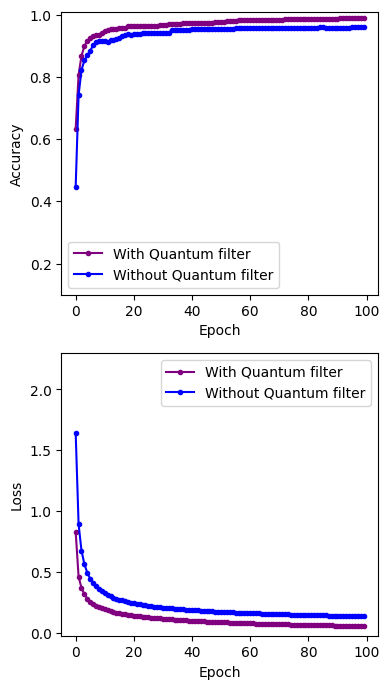

In [23]:
import matplotlib.pyplot as plt


fig, (ax1, ax2) = plt.subplots(2, 1, figsize=(4, 7))

ax1.plot(q_history.history["accuracy"], "-ob", label="With Quantum filter",marker='.', linestyle='-', color='purple')
ax1.plot(c_history.history["accuracy"], "-og", label="Without Quantum filter",marker='.', linestyle='-', color='blue')
ax1.set_ylabel("Accuracy")
ax1.set_ylim([0.1, 1.01])
ax1.set_xlabel("Epoch")
ax1.legend()

ax2.plot(q_history.history["loss"], "-ob", label="With Quantum filter",marker='.', linestyle='-', color='purple')
ax2.plot(c_history.history["loss"], "-og", label="Without Quantum filter",marker='.', linestyle='-', color='blue')
ax2.set_ylabel("Loss")
ax2.set_ylim(top=2.3)
ax2.set_xlabel("Epoch")
ax2.legend()
plt.tight_layout()
plt.show()

In [24]:
import qiskit
import qiskit_aer
import qiskit_machine_learning
from qiskit_machine_learning.neural_networks import EstimatorQNN
from qiskit_machine_learning.connectors import TorchConnector
from qiskit_machine_learning.circuit.library import QNNCircuit

print("Qiskit:", qiskit.__version__)           # should be 0.45.3
print("Qiskit-Aer:", qiskit_aer.__version__)   # should be 0.13.3
print("Qiskit-ML:", qiskit_machine_learning.__version__)  # should be 0.7.2
print("✅ All imports OK")

Qiskit: 0.45.3
Qiskit-Aer: 0.13.3
Qiskit-ML: 0.7.2
✅ All imports OK


In [25]:
# Pytorch
import torch, torchvision, torch.utils
from torch import Tensor
from torch import cat
from torch.autograd.grad_mode import no_grad
from torch.utils.data import DataLoader
from torchvision import datasets, transforms
import torch.optim as optim
from torch.nn import (
    Module,
    Conv2d,
    Linear,
    Dropout2d,
    NLLLoss, BCELoss, CrossEntropyLoss, MSELoss,
    MaxPool2d,
    Flatten,
    Sequential,
    ReLU,
)
import torch.nn.functional as F

# Qiskit (current primitives-based API — Aer and QuantumInstance are removed)
from qiskit import QuantumCircuit
from qiskit.circuit import Parameter
from qiskit.circuit.library import RealAmplitudes, ZZFeatureMap, ZFeatureMap
from qiskit.quantum_info import DensityMatrix, entanglement_of_formation
from qiskit.visualization import plot_state_city
from qiskit_machine_learning.circuit.library import QNNCircuit
from qiskit_machine_learning.neural_networks import SamplerQNN, EstimatorQNN
from qiskit_machine_learning.connectors import TorchConnector


In [26]:
op_train_loaded = np.load(TRAIN_CACHE)
op_test_loaded  = np.load(TEST_CACHE)

In [27]:
op_train_py = np.transpose(op_train_loaded, (0, 3, 1, 2))
print(op_train_py.shape)


(600, 4, 14, 14)


In [28]:
op_test_py = np.transpose(op_test_loaded, (0, 3, 1, 2))
print(op_test_py.shape)

(120, 4, 14, 14)


In [29]:
import torch

# 将op_train和op_test转换为PyTorch张量
op_train_tensor = torch.tensor(op_train_py)
op_test_tensor = torch.tensor(op_test_py)

# 创建包含图像张量和标签的元组
train_data = [(op_train_tensor[i], train_labels[i]) for i in range(len(op_train_tensor))]
test_data = [(op_test_tensor[i], test_labels[i]) for i in range(len(op_test_tensor))]

# 打印转换后的第一个元组，检查格式是否正确
print(train_data[0])


(tensor([[[ 0.6596,  0.6596,  0.6596,  0.6596,  0.6596,  0.6596,  0.6596,
           0.6596,  0.6596,  0.6596,  0.6596,  0.6596,  0.6596,  0.6596],
         [ 0.6596,  0.6596,  0.6596,  0.6596,  0.6596,  0.6596,  0.6596,
           0.6596,  0.6596,  0.6596,  0.6596,  0.6596,  0.6596,  0.6596],
         [ 0.6596,  0.6596,  0.6596,  0.6596,  0.6596,  0.5886,  0.1805,
          -0.6594, -0.6594, -0.6594,  0.6578,  0.6596,  0.6596,  0.6596],
         [ 0.6596,  0.6596,  0.6596,  0.6596, -0.3844, -0.4744,  0.4171,
           0.6448,  0.6375,  0.6375,  0.6375,  0.5515,  0.6596,  0.6596],
         [ 0.6596,  0.6596,  0.6596,  0.6596,  0.6588, -0.6387, -0.8023,
          -0.6165, -0.6083,  0.6375,  0.3224,  0.1120,  0.6596,  0.6596],
         [ 0.6596,  0.6596,  0.6596,  0.6596,  0.6596,  0.6596,  0.6596,
           0.6596, -0.4533,  0.5675, -0.6706,  0.6596,  0.6596,  0.6596],
         [ 0.6596,  0.6596,  0.6596,  0.6596,  0.6090, -0.4764, -0.4764,
          -0.8027,  0.5996, -0.2249, -0.8705

In [30]:
train_loader = DataLoader(train_data, shuffle=True, batch_size=1)
test_loader = DataLoader(test_data, shuffle= True, batch_size=1)

In [31]:
for batch_idx, (data, target) in enumerate(train_loader):
    print("Batch Index:", batch_idx)
    print("Data Shape:", data.shape)
    print("Target Shape:", target.shape)

Batch Index: 0
Data Shape: torch.Size([1, 4, 14, 14])
Target Shape: torch.Size([1])
Batch Index: 1
Data Shape: torch.Size([1, 4, 14, 14])
Target Shape: torch.Size([1])
Batch Index: 2
Data Shape: torch.Size([1, 4, 14, 14])
Target Shape: torch.Size([1])
Batch Index: 3
Data Shape: torch.Size([1, 4, 14, 14])
Target Shape: torch.Size([1])
Batch Index: 4
Data Shape: torch.Size([1, 4, 14, 14])
Target Shape: torch.Size([1])
Batch Index: 5
Data Shape: torch.Size([1, 4, 14, 14])
Target Shape: torch.Size([1])
Batch Index: 6
Data Shape: torch.Size([1, 4, 14, 14])
Target Shape: torch.Size([1])
Batch Index: 7
Data Shape: torch.Size([1, 4, 14, 14])
Target Shape: torch.Size([1])
Batch Index: 8
Data Shape: torch.Size([1, 4, 14, 14])
Target Shape: torch.Size([1])
Batch Index: 9
Data Shape: torch.Size([1, 4, 14, 14])
Target Shape: torch.Size([1])
Batch Index: 10
Data Shape: torch.Size([1, 4, 14, 14])
Target Shape: torch.Size([1])
Batch Index: 11
Data Shape: torch.Size([1, 4, 14, 14])
Target Shape: torch.

In [32]:
# === Step 1: 创建 QNN ===
def create_qnn():
    feature_map = ZZFeatureMap(2)
    ansatz = RealAmplitudes(2, reps=1)
    qc = QuantumCircuit(2)
    qc.compose(feature_map, inplace=True)
    qc.compose(ansatz, inplace=True)
    qnn = EstimatorQNN(
        circuit=qc,
        input_params=feature_map.parameters,
        weight_params=ansatz.parameters,
        input_gradients=True,
    )
    return qnn

# === STEP 2: 定义模型结构 ===
class Net(Module):
    def __init__(self, qnn):
        super().__init__()
        self.conv1 = Conv2d(4, 8, 3)
        self.conv2 = Conv2d(8, 16, 3)
        self.dropout = Dropout2d()
        self.fc2 = None
        self.qnn = TorchConnector(qnn)
        self.fc3 = Linear(1, 2)

    def forward(self, x):
        x = F.relu(self.conv1(x))
        x = F.max_pool2d(x, 2)
        x = F.relu(self.conv2(x))
        x = F.max_pool2d(x, 2)
        x = self.dropout(x)
        x = x.view(x.shape[0], -1)
        if self.fc2 is None:
            self.fc2 = Linear(x.shape[1], 2).to(x.device)
        x = self.fc2(x)
        x = self.qnn(x)
        x = self.fc3(x)
        return x

In [33]:
DEVICE = 'cuda' if torch.cuda.is_available() else 'cpu'
print(f"Using device: {DEVICE}")

def train_qcq_cnn(train_loader, epochs=30, seed=42, lr=0.0005):
    import numpy as np, random
    from torch.nn.utils import clip_grad_norm_

    start_time = time.time()

    torch.manual_seed(seed)
    np.random.seed(seed)
    random.seed(seed)
    torch.cuda.manual_seed_all(seed)

    qnn = create_qnn()
    model = Net(qnn).to(DEVICE)
    optimizer = optim.Adam(model.parameters(), lr=lr)
    loss_func = torch.nn.CrossEntropyLoss().to(DEVICE)

    loss_list, acc_list = [], []

    model.train()
    for epoch in range(epochs):
        correct = 0
        total_loss = []
        for data, target in train_loader:
            optimizer.zero_grad(set_to_none=True)
            output = model(data.to(DEVICE))
            loss = loss_func(output, target.to(DEVICE).long())
            loss.backward()
            clip_grad_norm_(model.parameters(), max_norm=1.0)
            optimizer.step()
            total_loss.append(loss.item())
            pred = output.argmax(dim=1)
            correct += pred.eq(target.to(DEVICE)).sum().item()

        epoch_loss = sum(total_loss) / len(total_loss)
        epoch_acc = 100. * correct / len(train_loader)
        loss_list.append(epoch_loss)
        acc_list.append(epoch_acc)

        print(f"[{epoch+1:3d}/{epochs}] Loss: {epoch_loss:.4f} | Accuracy: {epoch_acc:.2f}%")

    elapsed_time = time.time() - start_time
    print(f"\nTotal training time: {elapsed_time:.2f} seconds")

    return model, loss_list, acc_list


Using device: cuda


In [34]:
from sklearn.metrics import confusion_matrix
import seaborn as sns
import matplotlib.pyplot as plt
import numpy as np

def plot_confusion_matrix_percent(model, test_loader, class_names=["Class 0", "Class 1"]):
    model.eval()
    all_preds = []
    all_labels = []
    with torch.no_grad():
        for data, target in test_loader:
            output = model(data.to(DEVICE))
            preds = output.argmax(dim=1).cpu()
            all_preds.extend(preds.numpy())
            all_labels.extend(target.numpy())

    cm = confusion_matrix(all_labels, all_preds)
    cm_percent = cm.astype("float") / cm.sum(axis=1)[:, np.newaxis] * 100

    plt.figure(figsize=(6, 5))
    sns.heatmap(cm_percent, annot=True, fmt=".1f", cmap="Blues",
                xticklabels=class_names, yticklabels=class_names)
    plt.ylabel("True Label", fontsize=13)
    plt.xlabel("Predicted Label", fontsize=13)
    plt.title("Confusion Matrix (Percentage)", fontsize=14)
    plt.tight_layout()
    plt.show()


In [35]:
model1, loss1, acc1 = train_qcq_cnn(train_loader, epochs=QCQ_EPOCHS, seed=QCQ_SEED, lr=QCQ_LR)


[  1/100] Loss: 0.6904 | Accuracy: 53.33%
[  2/100] Loss: 0.6574 | Accuracy: 66.67%
[  3/100] Loss: 0.5980 | Accuracy: 75.00%
[  4/100] Loss: 0.5450 | Accuracy: 77.83%
[  5/100] Loss: 0.4924 | Accuracy: 81.33%
[  6/100] Loss: 0.4721 | Accuracy: 79.17%
[  7/100] Loss: 0.4535 | Accuracy: 80.67%
[  8/100] Loss: 0.4289 | Accuracy: 82.50%
[  9/100] Loss: 0.4138 | Accuracy: 80.67%
[ 10/100] Loss: 0.3309 | Accuracy: 87.83%
[ 11/100] Loss: 0.4015 | Accuracy: 83.33%
[ 12/100] Loss: 0.3570 | Accuracy: 87.17%
[ 13/100] Loss: 0.3328 | Accuracy: 86.00%
[ 14/100] Loss: 0.3732 | Accuracy: 85.83%
[ 15/100] Loss: 0.3043 | Accuracy: 87.83%
[ 16/100] Loss: 0.3364 | Accuracy: 86.67%
[ 17/100] Loss: 0.3336 | Accuracy: 87.33%
[ 18/100] Loss: 0.2889 | Accuracy: 87.67%
[ 19/100] Loss: 0.2030 | Accuracy: 92.83%
[ 20/100] Loss: 0.2694 | Accuracy: 90.33%
[ 21/100] Loss: 0.2383 | Accuracy: 90.83%
[ 22/100] Loss: 0.2783 | Accuracy: 89.33%
[ 23/100] Loss: 0.2208 | Accuracy: 92.33%
[ 24/100] Loss: 0.2521 | Accuracy:

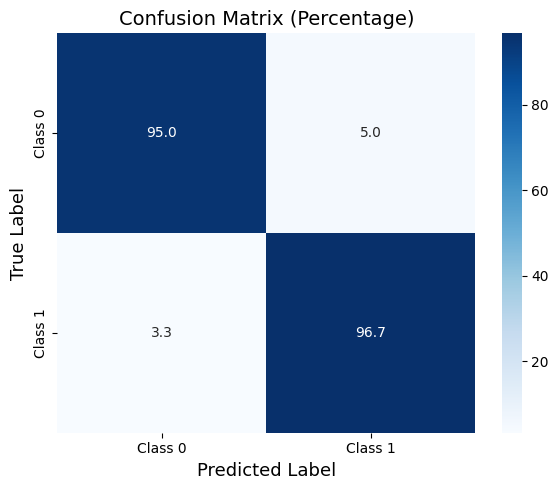

In [36]:
plot_confusion_matrix_percent(model1, test_loader)


In [37]:
print("Loss per epoch:")
for l in loss1:
    print(f"{l:.4f}")


Loss per epoch:
0.6904
0.6574
0.5980
0.5450
0.4924
0.4721
0.4535
0.4289
0.4138
0.3309
0.4015
0.3570
0.3328
0.3732
0.3043
0.3364
0.3336
0.2889
0.2030
0.2694
0.2383
0.2783
0.2208
0.2521
0.2381
0.2520
0.1828
0.2771
0.1824
0.1637
0.2255
0.2048
0.2355
0.2059
0.1683
0.1966
0.2052
0.1978
0.1768
0.1946
0.1837
0.1346
0.1441
0.1594
0.0538
0.1972
0.1384
0.0978
0.1054
0.1535
0.1387
0.1541
0.0995
0.1412
0.2192
0.1225
0.1319
0.0865
0.1470
0.1001
0.1344
0.0768
0.0996
0.0917
0.1199
0.0835
0.0837
0.1493
0.1659
0.0447
0.0817
0.1351
0.0585
0.1137
0.1504
0.0850
0.0858
0.1035
0.0976
0.0673
0.0781
0.1299
0.0739
0.0963
0.0578
0.0757
0.0615
0.0548
0.0300
0.0574
0.0409
0.1028
0.0818
0.0706
0.0986
0.0901
0.0539
0.0513
0.0751
0.0508


In [38]:
print("Accuracy per epoch:")
for a in acc1:
    print(f"{a/100:.4f}")


Accuracy per epoch:
0.5333
0.6667
0.7500
0.7783
0.8133
0.7917
0.8067
0.8250
0.8067
0.8783
0.8333
0.8717
0.8600
0.8583
0.8783
0.8667
0.8733
0.8767
0.9283
0.9033
0.9083
0.8933
0.9233
0.9117
0.9167
0.9083
0.9417
0.9133
0.9450
0.9433
0.9383
0.9317
0.9283
0.9383
0.9350
0.9400
0.9417
0.9467
0.9367
0.9383
0.9417
0.9617
0.9550
0.9483
0.9750
0.9500
0.9567
0.9683
0.9683
0.9550
0.9617
0.9617
0.9617
0.9667
0.9433
0.9633
0.9600
0.9750
0.9600
0.9683
0.9583
0.9767
0.9633
0.9683
0.9617
0.9767
0.9650
0.9600
0.9550
0.9833
0.9767
0.9683
0.9817
0.9700
0.9683
0.9700
0.9717
0.9667
0.9683
0.9733
0.9700
0.9667
0.9800
0.9750
0.9850
0.9800
0.9817
0.9817
0.9867
0.9817
0.9833
0.9750
0.9833
0.9817
0.9750
0.9817
0.9867
0.9817
0.9800
0.9833


In [40]:
# Feasibility run: single seed only (skip multi-seed violin plot loop)
import pandas as pd

seed = 42
results = []
for epoch, loss in enumerate(loss1):
    results.append({
        'Seed': seed,
        'Epoch': epoch + 1,
        'Loss': loss,
        'Dataset': 'MNIST'
    })

df = pd.DataFrame(results)
df.to_excel("qcqcnn_loss_MNIST.xlsx", index=False)
print(df)


    Seed  Epoch      Loss Dataset
0     42      1  0.690422   MNIST
1     42      2  0.657377   MNIST
2     42      3  0.598044   MNIST
3     42      4  0.544975   MNIST
4     42      5  0.492429   MNIST
..   ...    ...       ...     ...
95    42     96  0.090123   MNIST
96    42     97  0.053904   MNIST
97    42     98  0.051271   MNIST
98    42     99  0.075063   MNIST
99    42    100  0.050838   MNIST

[100 rows x 4 columns]


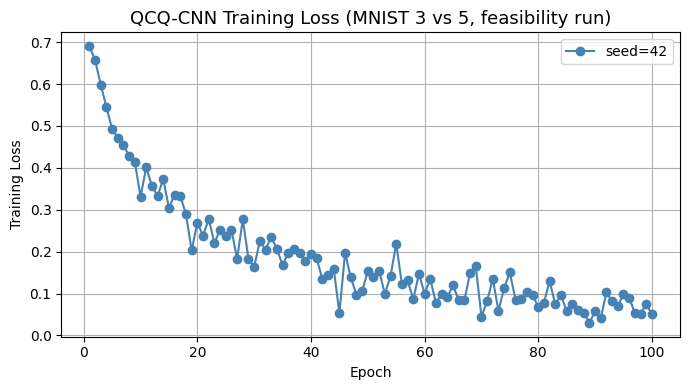

In [41]:
# Simple loss plot (replaces multi-seed violin plot for feasibility run)
import matplotlib.pyplot as plt

plt.figure(figsize=(7, 4))
plt.plot(range(1, len(loss1) + 1), loss1, marker='o', color='steelblue', label='seed=42')
plt.title("QCQ-CNN Training Loss (MNIST 3 vs 5, feasibility run)", fontsize=13)
plt.xlabel("Epoch")
plt.ylabel("Training Loss")
plt.legend()
plt.grid(True)
plt.tight_layout()
plt.savefig("loss_qcqcnn_feasibility.png", dpi=150)
plt.show()


  EXPERIMENT SUMMARY
  MNIST 3 vs 5  |  600 train / 120 test  |  seed=42  |  TF=100ep  QCQ=100ep

[ 1. FINAL EPOCH METRICS ]
Model                   Train Acc  Val/Test Acc   Train Loss   Val Loss
----------------------------------------------------------------------
Q+Dense                    0.9900        0.9167       0.0570     0.1665
Classical Dense            0.9600        0.9083       0.1371     0.2229
QC-CNN                     1.0000        0.9667       0.0000     0.1776
Classical CNN              1.0000        0.9750       0.0000     0.1204
QCQ-CNN (PyTorch)          0.9833        0.9583       0.0508          —

[ 2. PEAK VALIDATION / TEST ACCURACY ]
Model                    Peak Acc   At Epoch
---------------------------------------------
Q+Dense                    0.9167         59
Classical Dense            0.9167         34
QC-CNN                     0.9833          2
Classical CNN              0.9750         33
QCQ-CNN                    0.9867         89  (train acc)

[ 

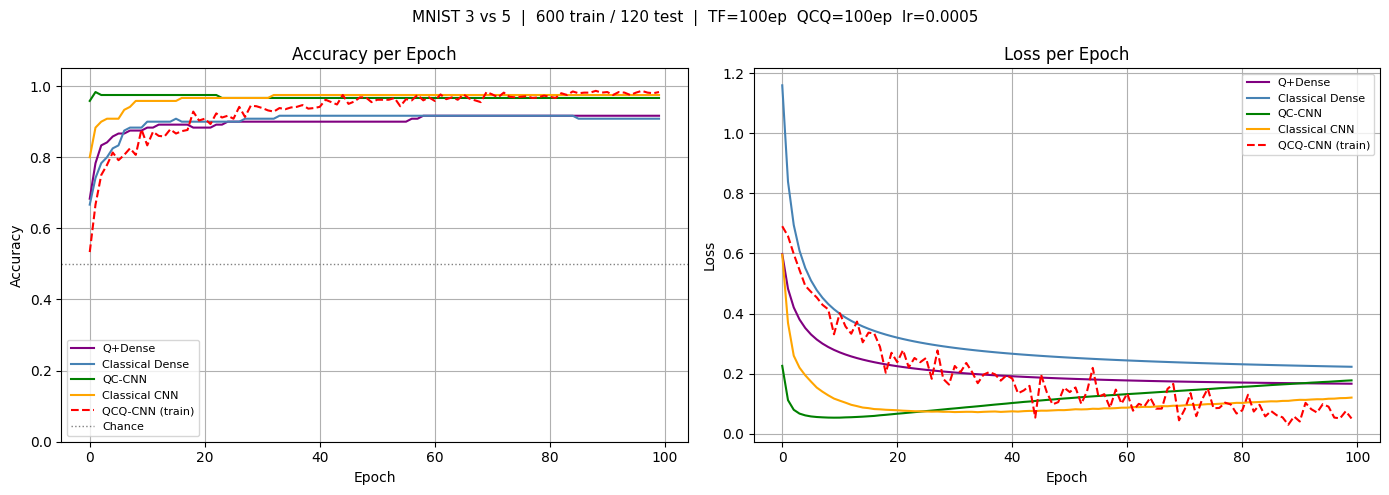

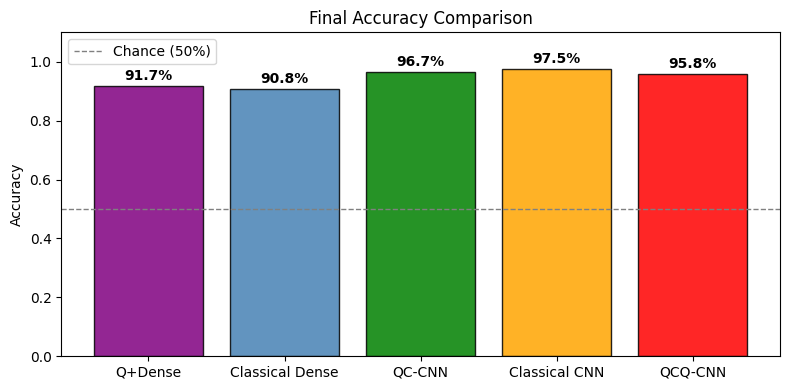

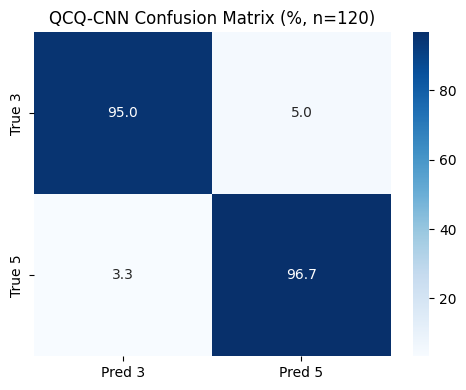

Saved: results_summary.png | results_bar.png | qcqcnn_confusion.png


In [42]:
# ================================================================
#  RESULTS SUMMARY — all models collected in one place
# ================================================================
import matplotlib.pyplot as plt
import numpy as np
import torch
from sklearn.metrics import classification_report, confusion_matrix
import seaborn as sns

SEPARATOR = "=" * 68

# --- Evaluate QCQ-CNN on the test set (PyTorch model has no val loop) ---
model1.eval()
qcq_preds, qcq_true = [], []
with torch.no_grad():
    for data, target in test_loader:
        out = model1(data.to(DEVICE))
        qcq_preds.extend(out.argmax(dim=1).cpu().numpy())
        qcq_true.extend(target.numpy())
qcq_test_acc  = float(np.mean(np.array(qcq_preds) == np.array(qcq_true)))
qcq_test_err  = 1.0 - qcq_test_acc

# --- Helper: first epoch >= threshold ---
def epoch_first_above(values, threshold):
    for i, v in enumerate(values):
        if v >= threshold:
            return i + 1
    return None

# --- Collect TF model results ---
tf_models = {
    'Q+Dense':         q_history,
    'Classical Dense': c_history,
    'QC-CNN':          qccnn_history,
    'Classical CNN':   cnn_history,
}

# ----------------------------------------------------------------
print(SEPARATOR)
print("  EXPERIMENT SUMMARY")
print(f"  MNIST {TARGET_LABELS[0]} vs {TARGET_LABELS[1]}  |  "
      f"{PER_CLASS_TRAIN*2} train / {PER_CLASS_TEST*2} test  |  "
      f"seed={QCQ_SEED}  |  TF={TF_EPOCHS}ep  QCQ={QCQ_EPOCHS}ep")
print(SEPARATOR)

# ---- 1. Final epoch metrics ----
print("\n[ 1. FINAL EPOCH METRICS ]")
print(f"{'Model':<22} {'Train Acc':>10} {'Val/Test Acc':>13} {'Train Loss':>12} {'Val Loss':>10}")
print("-" * 70)
for name, h in tf_models.items():
    ta = h.history['accuracy'][-1]
    va = h.history['val_accuracy'][-1]
    tl = h.history['loss'][-1]
    vl = h.history['val_loss'][-1]
    print(f"{name:<22} {ta:>10.4f} {va:>13.4f} {tl:>12.4f} {vl:>10.4f}")
print(f"{'QCQ-CNN (PyTorch)':<22} {acc1[-1]/100:>10.4f} {qcq_test_acc:>13.4f} "
      f"{loss1[-1]:>12.4f} {'—':>10}")

# ---- 2. Peak validation/test accuracy ----
print("\n[ 2. PEAK VALIDATION / TEST ACCURACY ]")
print(f"{'Model':<22} {'Peak Acc':>10} {'At Epoch':>10}")
print("-" * 45)
for name, h in tf_models.items():
    peak  = max(h.history['val_accuracy'])
    epoch = h.history['val_accuracy'].index(peak) + 1
    print(f"{name:<22} {peak:>10.4f} {epoch:>10}")
peak_qcq  = max(acc1) / 100
epoch_qcq = acc1.index(max(acc1)) + 1
print(f"{'QCQ-CNN':<22} {peak_qcq:>10.4f} {epoch_qcq:>10}  (train acc)")

# ---- 3. Epochs to reach 80 % ----
print("\n[ 3. EPOCHS TO FIRST REACH 80% ACCURACY ]")
print(f"{'Model':<22} {'Epoch':>8}")
print("-" * 33)
for name, h in tf_models.items():
    e = epoch_first_above(h.history['val_accuracy'], 0.80)
    print(f"{name:<22} {str(e) if e else 'never':>8}")
e_qcq = epoch_first_above([a/100 for a in acc1], 0.80)
print(f"{'QCQ-CNN':<22} {str(e_qcq)+' (train)' if e_qcq else 'never':>8}")

# ---- 4. Convergence stability (std of last 10 epoch val acc) ----
print("\n[ 4. CONVERGENCE STABILITY — std(val_acc) over last 10 epochs ]")
print(f"{'Model':<22} {'Std Dev':>10}  (lower = more stable)")
print("-" * 40)
for name, h in tf_models.items():
    std = float(np.std(h.history['val_accuracy'][-10:]))
    print(f"{name:<22} {std:>10.4f}")
std_qcq = float(np.std([a/100 for a in acc1[-10:]]))
print(f"{'QCQ-CNN':<22} {std_qcq:>10.4f}  (train acc)")

# ---- 5. Error rate ----
print("\n[ 5. FINAL ERROR RATE (1 - val/test acc) ]")
print(f"{'Model':<22} {'Error Rate':>12}")
print("-" * 37)
for name, h in tf_models.items():
    err = 1.0 - h.history['val_accuracy'][-1]
    print(f"{name:<22} {err:>12.4f}")
print(f"{'QCQ-CNN':<22} {qcq_test_err:>12.4f}  (test set)")

# ---- 6. QCQ-CNN classification report ----
print("\n[ 6. QCQ-CNN CLASSIFICATION REPORT (test set) ]")
print(classification_report(
    qcq_true, qcq_preds,
    target_names=[f'Digit {TARGET_LABELS[0]}', f'Digit {TARGET_LABELS[1]}']
))

print(SEPARATOR)

# ================================================================
# PLOTS
# ================================================================
colors = {
    'Q+Dense':         'purple',
    'Classical Dense': 'steelblue',
    'QC-CNN':          'green',
    'Classical CNN':   'orange',
}

# --- Plot 1: Val accuracy + loss curves ---
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(14, 5))

for name, h in tf_models.items():
    ax1.plot(h.history['val_accuracy'], label=name, color=colors[name])
    ax2.plot(h.history['val_loss'],     label=name, color=colors[name])

ax1.plot([a/100 for a in acc1], label='QCQ-CNN (train)', color='red', linestyle='--')
ax2.plot(loss1,                  label='QCQ-CNN (train)', color='red', linestyle='--')

ax1.axhline(0.5, color='gray', linestyle=':', linewidth=1, label='Chance')
ax1.set_title('Accuracy per Epoch'); ax1.set_xlabel('Epoch'); ax1.set_ylabel('Accuracy')
ax1.legend(fontsize=8); ax1.grid(True); ax1.set_ylim([0, 1.05])

ax2.set_title('Loss per Epoch'); ax2.set_xlabel('Epoch'); ax2.set_ylabel('Loss')
ax2.legend(fontsize=8); ax2.grid(True)

fig.suptitle(
    f"MNIST {TARGET_LABELS[0]} vs {TARGET_LABELS[1]}  |  "
    f"{PER_CLASS_TRAIN*2} train / {PER_CLASS_TEST*2} test  |  "
    f"TF={TF_EPOCHS}ep  QCQ={QCQ_EPOCHS}ep  lr={QCQ_LR}",
    fontsize=11
)
plt.tight_layout()
plt.savefig('results_summary.png', dpi=150)
plt.show()

# --- Plot 2: Bar chart of final val/test accuracy ---
model_names = list(tf_models.keys()) + ['QCQ-CNN']
final_accs  = [tf_models[n].history['val_accuracy'][-1] for n in tf_models] + [qcq_test_acc]
bar_colors  = [colors[n] for n in tf_models] + ['red']

fig2, ax3 = plt.subplots(figsize=(8, 4))
bars = ax3.bar(model_names, final_accs, color=bar_colors, edgecolor='black', alpha=0.85)
ax3.axhline(0.5, color='gray', linestyle='--', linewidth=1, label='Chance (50%)')
for bar, val in zip(bars, final_accs):
    ax3.text(bar.get_x() + bar.get_width()/2, bar.get_height() + 0.01,
             f'{val:.1%}', ha='center', va='bottom', fontsize=10, fontweight='bold')
ax3.set_ylim([0, 1.1]); ax3.set_ylabel('Accuracy'); ax3.set_title('Final Accuracy Comparison')
ax3.legend(); plt.tight_layout()
plt.savefig('results_bar.png', dpi=150)
plt.show()

# --- Plot 3: QCQ-CNN confusion matrix ---
cm     = confusion_matrix(qcq_true, qcq_preds)
cm_pct = cm.astype(float) / cm.sum(axis=1)[:, None] * 100

fig3, ax4 = plt.subplots(figsize=(5, 4))
sns.heatmap(cm_pct, annot=True, fmt='.1f', cmap='Blues',
            xticklabels=[f'Pred {TARGET_LABELS[0]}', f'Pred {TARGET_LABELS[1]}'],
            yticklabels=[f'True {TARGET_LABELS[0]}', f'True {TARGET_LABELS[1]}'], ax=ax4)
ax4.set_title(f'QCQ-CNN Confusion Matrix (%, n={len(qcq_true)})')
plt.tight_layout()
plt.savefig('qcqcnn_confusion.png', dpi=150)
plt.show()

print("Saved: results_summary.png | results_bar.png | qcqcnn_confusion.png")
